In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import brentq
from scipy.integrate import simpson
from scipy.linalg import solve

# ==========================================
# CLP: Mode Matching for a Slab-Waveguide Step
# Set B parameters (all lengths in micrometres)
# ==========================================

lambda0 = 1.55       # Vacuum wavelength (um)
n_core = 3.40        # Core refractive index
n_clad = 1.45        # Cladding refractive index

d1 = 0.90            # Input core width (um)
d2 = 0.60            # Output core width (um)

k0 = 2 * np.pi / lambda0

print(f"Vacuum wavelength = {lambda0:.3f} um")
print(f"Free-space wavenumber k0 = {k0:.6f} rad/um")
print(f"Core index = {n_core}")
print(f"Cladding index = {n_clad}")
print(f"Input width = {d1:.3f} um")
print(f"Output width = {d2:.3f} um")


Vacuum wavelength = 1.550 um
Free-space wavenumber k0 = 4.053668 rad/um
Core index = 3.4
Cladding index = 1.45
Input width = 0.900 um
Output width = 0.600 um


In [ ]:

def solve_slab_modes(width, wavelength, n_core, n_clad):
    """
    Find guided TE modes of a symmetric dielectric slab.

    Coordinate x = 0 is at the centre of the slab.
    The core extends from -width/2 to +width/2.

    Returns a list of dictionaries containing:
        mode_index, parity, u, w, beta, neff
    """
    k0 = 2 * np.pi / wavelength
    half_width = width / 2

    V = k0 * half_width * np.sqrt(
        n_core**2 - n_clad**2
    )

    def even_equation(u):
        return u * np.tan(u) - np.sqrt(max(V**2 - u**2, 0.0))

    def odd_equation(u):
        return -u / np.tan(u) - np.sqrt(max(V**2 - u**2, 0.0))

    roots = []
    eps = 1e-9

    # Guided roots satisfy 0 < u < V.
    # Each interval avoids the poles of tan(u).
    m = 0
    while m * np.pi / 2 < V:
        left = m * np.pi / 2 + eps
        right = min((m + 1) * np.pi / 2 - eps, V - eps)

        if left < right:
            midpoint = (left + right) / 2

            if m % 2 == 0:
                equation = even_equation
                parity = "even"
            else:
                equation = odd_equation
                parity = "odd"

            f_left = equation(left)
            f_right = equation(right)

            if np.isfinite(f_left) and np.isfinite(f_right):
                if f_left * f_right < 0:
                    u = brentq(equation, left, right)

                    w = np.sqrt(V**2 - u**2)
                    beta = np.sqrt(
                        (k0 * n_core)**2
                        - (u / half_width)**2
                    )
                    neff = beta / k0

                    roots.append({
                        "mode_index": len(roots),
                        "parity": parity,
                        "u": u,
                        "w": w,
                        "beta": beta,
                        "neff": neff,
                        "V": V,
                        "width": width,
                    })

        m += 1

    return roots


modes_in = solve_slab_modes(
    d1, lambda0, n_core, n_clad
)

modes_out = solve_slab_modes(
    d2, lambda0, n_core, n_clad
)


def print_modes(label, modes):
    print(f"\n{label}")
    print("-" * 65)
    print(f"{'Mode':<8}{'Parity':<10}{'beta (rad/um)':<20}{'neff':<12}")

    for mode in modes:
        print(
            f"TE{mode['mode_index']:<5}"
            f"{mode['parity']:<10}"
            f"{mode['beta']:<20.6f}"
            f"{mode['neff']:<12.6f}"
        )

    print(f"Number of guided modes found: {len(modes)}")


print_modes("Input slab (d1 = 0.90 um)", modes_in)
print_modes("Output slab (d2 = 0.60 um)", modes_out)



Input slab (d1 = 0.90 um)
-----------------------------------------------------------------
Mode    Parity    beta (rad/um)       neff        
TE0    even      13.461251           3.320758    
TE1    odd       12.461391           3.074103    
TE2    even      10.653282           2.628060    
TE3    odd       7.748025            1.911362    
Number of guided modes found: 4

Output slab (d2 = 0.60 um)
-----------------------------------------------------------------
Mode    Parity    beta (rad/um)       neff        
TE0    even      13.153916           3.244942    
TE1    odd       11.143309           2.748945    
TE2    even      7.332820            1.808935    
Number of guided modes found: 3


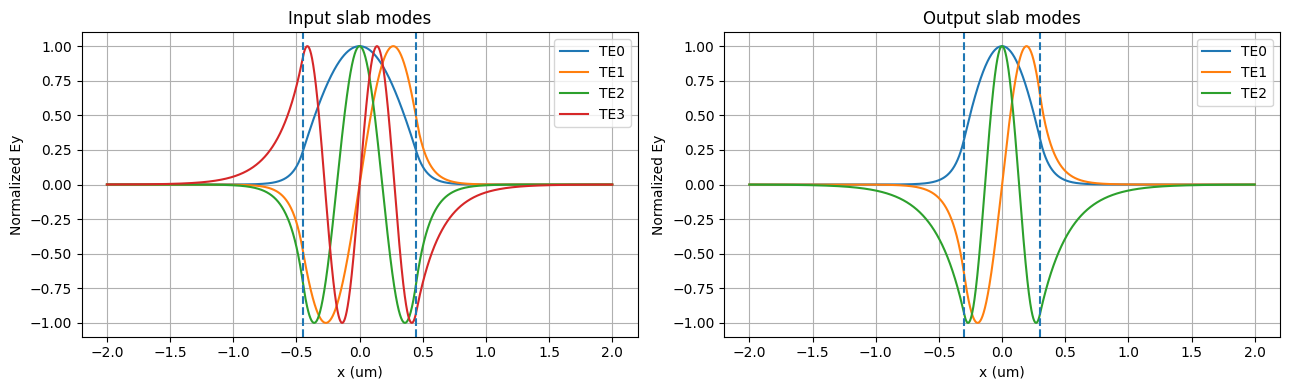

In [ ]:


def mode_profile(mode, x, n_core, n_clad):
    """
    Return the scalar TE electric-field profile Ey(x).
    Normalized to unit peak magnitude.

    Odd modes retain their sign in both cladding regions.
    """
    width = mode["width"]
    half_width = width / 2
    kx = mode["u"] / half_width
    alpha = mode["w"] / half_width

    x = np.asarray(x)
    ax = np.abs(x)

    if mode["parity"] == "even":
        core_field = np.cos(kx * x)
        edge_field = np.cos(kx * half_width)

        outside_field = edge_field * np.exp(
            -alpha * (ax - half_width)
        )

    else:
        core_field = np.sin(kx * x)
        edge_field = np.sin(kx * half_width)

        # Preserve odd symmetry in both cladding regions.
        outside_field = (
            np.sign(x) * edge_field
            * np.exp(-alpha * (ax - half_width))
        )

    field = np.where(
        ax <= half_width,
        core_field,
        outside_field
    )

    return field / np.max(np.abs(field))



x = np.linspace(-2.0, 2.0, 4001)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for mode in modes_in:
    axes[0].plot(
        x, mode_profile(mode, x, n_core, n_clad),
        label=f"TE{mode['mode_index']}"
    )

axes[0].axvline(-d1/2, linestyle="--")
axes[0].axvline(d1/2, linestyle="--")
axes[0].set_title("Input slab modes")
axes[0].set_xlabel("x (um)")
axes[0].set_ylabel("Normalized Ey")
axes[0].grid(True)
axes[0].legend()

for mode in modes_out:
    axes[1].plot(
        x, mode_profile(mode, x, n_core, n_clad),
        label=f"TE{mode['mode_index']}"
    )

axes[1].axvline(-d2/2, linestyle="--")
axes[1].axvline(d2/2, linestyle="--")
axes[1].set_title("Output slab modes")
axes[1].set_xlabel("x (um)")
axes[1].set_ylabel("Normalized Ey")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()


Cross-overlap matrix O (um):
[[ 0.438682  0.       -0.116218]
 [-0.        0.434824 -0.      ]
 [ 0.11391  -0.        0.497746]
 [-0.        0.180677 -0.      ]]


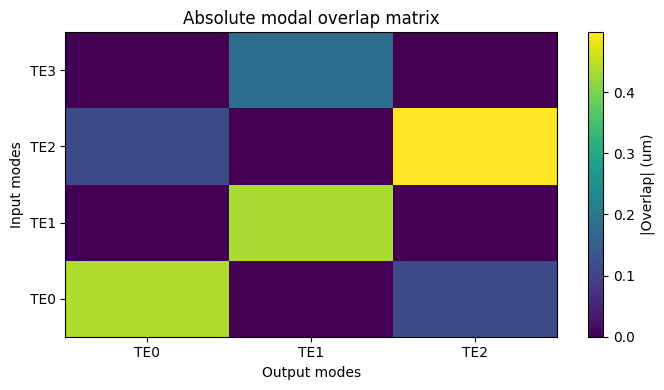


Overlap of incident TE0 with output modes:
TE0 (even): 0.43868172 um
TE1 (odd): 0.00000000 um
TE2 (even): -0.11621817 um


In [ ]:

# Cell 4: Calculate modal overlap integrals

# Use a wide transverse domain to capture the evanescent tails.
x_overlap = np.linspace(-5.0, 5.0, 20001)

# Calculate profiles for every guided mode.
profiles_in = np.array([
    mode_profile(m, x_overlap, n_core, n_clad)
    for m in modes_in
])

profiles_out = np.array([
    mode_profile(m, x_overlap, n_core, n_clad)
    for m in modes_out
])

# Cross-overlap matrix:
# rows = input modes, columns = output modes.
O = np.zeros((len(modes_in), len(modes_out)))

for m in range(len(modes_in)):
    for n in range(len(modes_out)):
        O[m, n] = simpson(
            profiles_in[m] * profiles_out[n],
            x=x_overlap
        )

print("Cross-overlap matrix O (um):")
print(np.array2string(O, precision=6, suppress_small=True))

# Plot the absolute overlap values.
plt.figure(figsize=(7, 4))
plt.imshow(np.abs(O), origin="lower", aspect="auto")
plt.colorbar(label="|Overlap| (um)")
plt.xticks(range(len(modes_out)),
           [f"TE{m['mode_index']}" for m in modes_out])
plt.yticks(range(len(modes_in)),
           [f"TE{m['mode_index']}" for m in modes_in])
plt.xlabel("Output modes")
plt.ylabel("Input modes")
plt.title("Absolute modal overlap matrix")
plt.tight_layout()
plt.show()

# Parity check for coupling from the incident fundamental mode.
print("\nOverlap of incident TE0 with output modes:")
for n, mode in enumerate(modes_out):
    print(
        f"TE{mode['mode_index']} ({mode['parity']}): "
        f"{O[0, n]:.8f} um"
    )


In [ ]:

# CELL 5: TE mode matching using overlap integrals and modal admittances

# 1. Calculate guided modes in the input and output waveguides
modes_in = solve_slab_modes(d1, lambda0, n_core, n_clad)
modes_out = solve_slab_modes(d2, lambda0, n_core, n_clad)

beta_in = np.array([m["beta"] for m in modes_in], dtype=float)
beta_out = np.array([m["beta"] for m in modes_out], dtype=float)

M = len(modes_in)
N = len(modes_out)

# 2. Calculate and L2-normalize the transverse mode profiles
x = np.linspace(-10.0, 10.0, 40001)

Phi_in = np.array([
    mode_profile(m, x, n_core, n_clad) for m in modes_in
], dtype=float)

Phi_out = np.array([
    mode_profile(m, x, n_core, n_clad) for m in modes_out
], dtype=float)

def normalize_modes(Phi, x):
    Phi_norm = np.zeros_like(Phi, dtype=float)
    for i in range(Phi.shape[0]):
        norm = np.sqrt(simpson(Phi[i]**2, x=x))
        if norm <= 0:
            raise ValueError(f"Mode {i} has a zero or invalid norm.")
        Phi_norm[i] = Phi[i] / norm
    return Phi_norm

Phi_in = normalize_modes(Phi_in, x)
Phi_out = normalize_modes(Phi_out, x)

# 3. Build the cross-waveguide overlap matrix:
# C[m,n] = integral(phi_in_m * phi_out_n dx)
C = np.zeros((M, N), dtype=float)

for m in range(M):
    for n in range(N):
        C[m, n] = simpson(
            Phi_in[m] * Phi_out[n], x=x
        )

# 4. Modal-admittance matrices.
# For scalar TE modes with the same permeability, admittance
# is proportional to beta, so the common factor cancels.
Y_in = np.diag(beta_in)
Y_out = np.diag(beta_out)

# 5. Incident wave: unit-amplitude fundamental input mode
a = np.zeros(M, dtype=float)
a[0] = 1.0

# Boundary equations:
# b = C @ e - a
# C.T @ Y_in @ (a - b) = Y_out @ e
#
# Combining them gives:
# (C.T @ Y_in @ C + Y_out) @ e = 2 * C.T @ Y_in @ a

system_matrix = C.T @ Y_in @ C + Y_out
rhs = 2.0 * C.T @ Y_in @ a

e = np.linalg.solve(system_matrix, rhs)
b = C @ e - a

# 6. Calculate guided-mode power fractions.
# With L2-normalized E-field profiles, modal power is proportional
# to beta * |amplitude|^2.
incident_power = beta_in[0] * abs(a[0])**2

R_modes = beta_in * np.abs(b)**2 / incident_power
T_modes = beta_out * np.abs(e)**2 / incident_power

R_guided = np.sum(R_modes)
T_guided = np.sum(T_modes)
power_sum = R_guided + T_guided

# 7. Display results
print("TE MODE-MATCHING RESULTS")
print("-" * 40)
print(f"Input guided modes:  {M}")
print(f"Output guided modes: {N}")
print(f"Overlap matrix shape: {C.shape}")

print("\nOverlap matrix C:")
print(np.round(C, 6))

print("\nReflection coefficients:")
for i, value in enumerate(b):
    print(f"r_TE{i} = {value:.8f}")

print("\nTransmission coefficients:")
for i, value in enumerate(e):
    print(f"t_TE{i} = {value:.8f}")

print("\nGuided-mode power fractions:")
for i, value in enumerate(R_modes):
    print(f"R_TE{i} = {value:.8f}")
for i, value in enumerate(T_modes):
    print(f"T_TE{i} = {value:.8f}")

print(f"\nTotal guided reflection R = {R_guided:.8f}")
print(f"Total guided transmission T = {T_guided:.8f}")
print(f"R + T = {power_sum:.8f}")
print(f"Guided-mode power balance = {100*power_sum:.4f}%")

if power_sum > 1.01:
    print("\nWARNING: Power exceeds the incident power by more than 1%.")
    print("Do not treat these results as validated; check conventions,")
    print("normalization, truncation, and the boundary equations.")
elif power_sum < 0.99:
    print("\nNOTE: Some power may be in radiation or omitted modes,")
    print("or the finite-mode approximation may need refinement.")
else:
    print("\nPower balance is close to unity, but FDTD comparison")
    print("and convergence checks are still required.")


TE MODE-MATCHING RESULTS
----------------------------------------
Input guided modes:  4
Output guided modes: 3
Overlap matrix shape: (4, 3)

Overlap matrix C:
[[ 0.968814  0.       -0.219144]
 [ 0.        0.92821  -0.      ]
 [ 0.244773 -0.        0.913216]
 [-0.        0.352385  0.      ]]

Reflection coefficients:
r_TE0 = 0.02116565
r_TE1 = 0.00000000
r_TE2 = -0.05400672
r_TE3 = -0.00000000

Transmission coefficients:
t_TE0 = 0.98117196
t_TE1 = -0.00000000
t_TE2 = -0.32212670

Guided-mode power fractions:
R_TE0 = 0.00044798
R_TE1 = 0.00000000
R_TE2 = 0.00230831
R_TE3 = 0.00000000
T_TE0 = 0.94071891
T_TE1 = 0.00000000
T_TE2 = 0.05652480

Total guided reflection R = 0.00275629
Total guided transmission T = 0.99724371
R + T = 1.00000000
Guided-mode power balance = 100.0000%

Power balance is close to unity, but FDTD comparison
and convergence checks are still required.


In [ ]:

# CELL 6: Diagnostic checks for the mode profiles and overlap matrix

# Check orthonormality within each waveguide
G_in = np.array([
    [simpson(Phi_in[i] * Phi_in[j], x=x)
     for j in range(len(modes_in))]
    for i in range(len(modes_in))
])

G_out = np.array([
    [simpson(Phi_out[i] * Phi_out[j], x=x)
     for j in range(len(modes_out))]
    for i in range(len(modes_out))
])

print("Input Gram matrix (should be close to identity):")
print(np.round(G_in, 5))

print("\nOutput Gram matrix (should be close to identity):")
print(np.round(G_out, 5))

print("\nOverlap matrix C:")
print(np.round(C, 5))

# For a centered symmetric slab, even-odd overlaps should be near zero
print("\nMaximum input even-to-output odd overlap:")
print(max(abs(C[0, 1]), abs(C[2, 1])))

print("\nMaximum input odd-to-output even overlap:")
print(max(abs(C[1, 0]), abs(C[1, 2]),
          abs(C[3, 0]), abs(C[3, 2])))

print("\nCurrent guided power balance:")
print(f"R = {R_guided:.8f}")
print(f"T = {T_guided:.8f}")
print(f"R + T = {R_guided + T_guided:.8f}")


Input Gram matrix (should be close to identity):
[[ 1.  0. -0.  0.]
 [ 0.  1. -0. -0.]
 [-0. -0.  1.  0.]
 [ 0. -0.  0.  1.]]

Output Gram matrix (should be close to identity):
[[ 1.  0. -0.]
 [ 0.  1.  0.]
 [-0.  0.  1.]]

Overlap matrix C:
[[ 0.96881  0.      -0.21914]
 [ 0.       0.92821 -0.     ]
 [ 0.24477 -0.       0.91322]
 [-0.       0.35238  0.     ]]

Maximum input even-to-output odd overlap:
5.778594262349227e-17

Maximum input odd-to-output even overlap:
7.240880224901261e-17

Current guided power balance:
R = 0.00275629
T = 0.99724371
R + T = 1.00000000


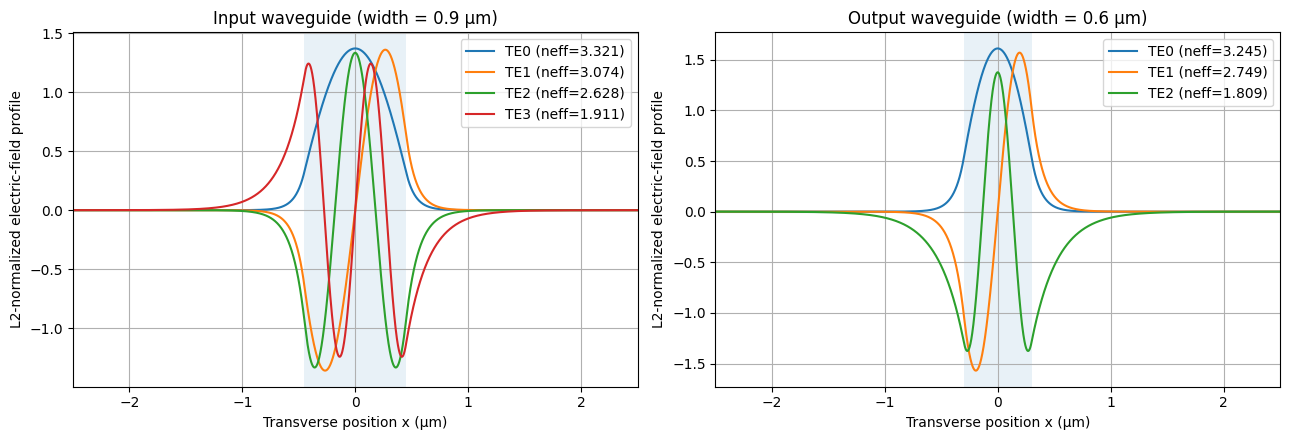

<Figure size 640x480 with 0 Axes>

In [ ]:

# CELL 7: Plot guided modes in the input and output waveguides

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Input waveguide
for i, mode in enumerate(modes_in):
    axes[0].plot(
        x, Phi_in[i],
        label=f"TE{i} (neff={mode['neff']:.3f})"
    )

axes[0].axvspan(-d1/2, d1/2, alpha=0.10)
axes[0].set_title(f"Input waveguide (width = {d1} µm)")
axes[0].set_xlabel("Transverse position x (µm)")
axes[0].set_ylabel("L2-normalized electric-field profile")
axes[0].grid(True)
axes[0].legend()

# Output waveguide
for i, mode in enumerate(modes_out):
    axes[1].plot(
        x, Phi_out[i],
        label=f"TE{i} (neff={mode['neff']:.3f})"
    )

axes[1].axvspan(-d2/2, d2/2, alpha=0.10)
axes[1].set_title(f"Output waveguide (width = {d2} µm)")
axes[1].set_xlabel("Transverse position x (µm)")
axes[1].set_ylabel("L2-normalized electric-field profile")
axes[0].set_xlim(-2.5, 2.5)
axes[1].set_xlim(-2.5, 2.5)
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()
plt.savefig("guided_mode_profiles.png", dpi=300, bbox_inches="tight")
